# Tennis with a serve advantage

The [tennis notebook](tennis.ipynb) gives each player one strength and the
same probability of winning a point whoever serves. It predicts who wins a set
well, but not how: it expects about 700 tie-breaks where the data have about
1,240, and too many one-sided sets. The missing piece is the **serve**. Players
hold serve far more often than they break, so sets are closer than a single
point probability implies.

This notebook adds **one global parameter**, the serve advantage $\delta$, and
compares the two models on the same 6,300 ATP sets. The set probabilities with
serve are computed by `maxlike.func.tennis.ServeSet`; the model is
`serve_model()` in [`docs/examples/tennis.py`](../examples/tennis.py).

## 1. Theory

### Point

With strengths $s$ ($\sum_i s_i = 0$) and the serve advantage $\delta$:

$$
p^{s}_{ij} = \sigma(s_i - s_j + \delta)\quad\text{(i wins a point on its own serve)},
\qquad
p^{r}_{ij} = \sigma(s_i - s_j - \delta) = 1 - p^{s}_{ji}\quad\text{(on j's serve)} .
$$

$\delta = 0$ gives back the model of the tennis notebook.

### Game

The game function is unchanged,
$G(p) = p^4(1 + 4q + 10q^2) + 20p^3q^3\cdot\frac{p^2}{1-2pq}$. Player $i$
**holds** with $g_{ij} = G(p^s_{ij})$ and **breaks** with
$b_{ij} = G(p^r_{ij}) = 1 - g_{ji}$.

### Set, with the serve alternating

Let $F$ be the player who serves the first game. Game $n$ is served by $F$ when
$n$ is odd and by the other player when it is even. With $w_n$ the probability
that $i$ wins game $n$ ($g$ or $b$, depending on the server), a recursion over
the score in games gives

$$
P(6\text{–}k) = P(\text{reach } 5\text{–}k)\,w_{6+k}\ (k \le 4),\quad
P(7\text{–}5) = P(\text{reach } 5\text{–}5)\,w_{11}\,w_{12},\quad
P(7\text{–}6) = P(\text{reach } 6\text{–}6)\,T .
$$

### Tie-break

$F$ serves its first point, then the serve alternates every two points
(1, 2–2, 2–2, …). A recursion over the points runs up to 6–6; from there each
pair of points has one serve of each player, so

$$
P(\text{win from } 6\text{–}6) = \frac{p^s p^r}{p^s p^r + (1-p^s)(1-p^r)} .
$$

### Who serves first

The data do not say, so each set is the average of the two cases:

$$
P_{ij}(k) = \tfrac12\,P_{ij}(k \mid F = i) + \tfrac12\,P_{ij}(k \mid F = j) .
$$

Sets are treated as independent, though within a match the first server of a
set depends on the previous one.

### Likelihood and exact derivatives

The likelihood is the multinomial over the 14 outcomes of a set between $i$
and $j$ (`NormalizedFinite`), as before. `ServeSet` carries every quantity of
the recursions as a second-order jet in $(p^s, p^r)$,
$(f, f_s, f_r, f_{ss}, f_{sr}, f_{rr})$, so the gradient and the Hessian are
exact; `maxlike` chains them through `Logistic` and the strengths.

### Comparing the two models

The base model is the serve model with $\delta = 0$ (nested), so the
likelihood-ratio statistic $2(\ell_1 - \ell_0)$ is $\chi^2_1$ under no serve
advantage.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chi2

import plot_style as ps          # also puts the package and the examples on the path
from plot_style import BLUE, ORANGE, AQUA, TEXT_2
from maxlike.func import Collapse
from maxlike.func.tennis import ServeSet, Game
from scipy.special import expit
import tennis as ex

ps.apply()
N, players = ex.load()
sets = pd.read_csv(ex.DATA)
print(len(sets), "sets,", len(players), "players")

6297 sets, 180 players


## 2. How the serve changes a set

Hold and break probabilities of two equal players, and the probability of a
tie-break, as the serve advantage grows (on the point-probability scale,
$\sigma(\delta)$ is the share of points won on serve):

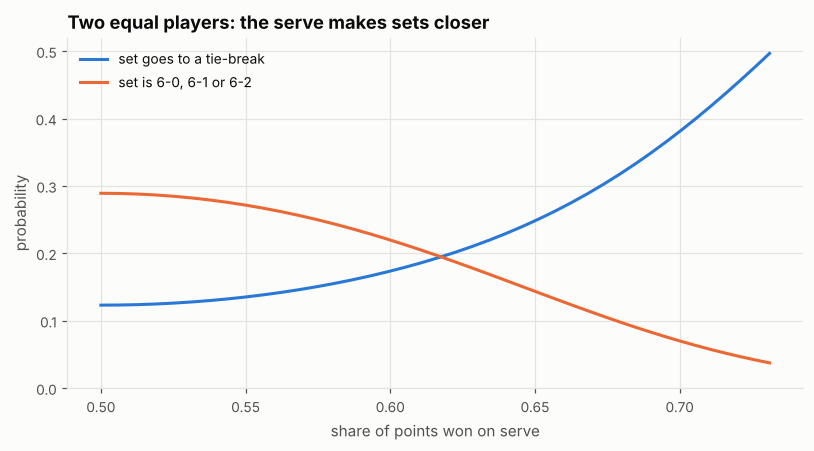

In [2]:
deltas = np.linspace(0, 1, 41)
ps_eq, pr_eq = expit(deltas), expit(-deltas)
scores = ServeSet()([ps_eq, pr_eq]).values               # i's 7 winning scores
tie = 2 * scores[:, -1]                                  # either player wins 7-6
one_sided = 2 * scores[:, :3].sum(-1)                    # 6-0, 6-1 or 6-2

fig, ax = plt.subplots()
ax.plot(ps_eq, tie, color=BLUE, label="set goes to a tie-break")
ax.plot(ps_eq, one_sided, color=ORANGE, label="set is 6-0, 6-1 or 6-2")
ax.set_ylim(0, None)
ps.finish(ax, "Two equal players: the serve makes sets closer",
          "share of points won on serve", "probability", legend=True)

## 3. Fits

Both models on the same data: the base model of the tennis notebook and the
model with the serve advantage.

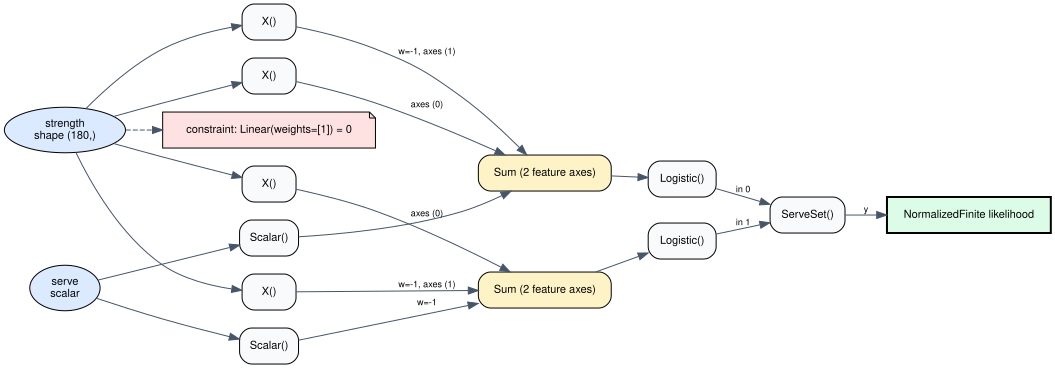

In [3]:
base = ex.fit(N, players)
serve = ex.fit_serve(N, players)
serve.graph()

The two logits differ only by the sign of the serve term; both pass through
`Logistic` into `ServeSet`.

In [4]:
def loglik(mle):
    P = mle.predict()
    return float((N * np.log(np.where(N > 0, P, 1))).sum())

l0, l1 = loglik(base), loglik(serve)
k0, k1 = len(players) - 1, len(players)
s = serve.summary()
delta, delta_se = s.loc[("serve", ""), ["estimate", "std_error"]]
print("serve advantage delta = %.3f +/- %.3f" % (delta, delta_se))
hold = Game()([np.array([expit(delta)])]).values.sum()
print("equal players: %.1f%% of points won on serve, hold %.1f%% of service games"
      % (100 * expit(delta), 100 * hold))
lr = 2 * (l1 - l0)
pd.DataFrame({"log-likelihood": [l0, l1], "free parameters": [k0, k1],
              "AIC": [2 * k0 - 2 * l0, 2 * k1 - 2 * l1]},
             index=["base (delta = 0)", "with serve"]).round(1)

serve advantage delta = 0.467 +/- 0.012
equal players: 61.5% of points won on serve, hold 76.6% of service games


,log-likelihood,free parameters,AIC
base (delta = 0),-15320.5,179,30998.9
with serve,-15085.9,180,30531.8


In [5]:
print("likelihood ratio %.1f, p-value %.1e" % (lr, chi2.sf(lr, 1)))

likelihood ratio 469.2, p-value 4.8e-104


The serve advantage is large and very precisely estimated: equal players win
about 61% of the points on their serve and hold about three service games
in four. The likelihood ratio is far beyond any significance threshold.

## 4. The shape of the sets

Given who won each set, how many sets of each score does each model expect?

,6-0,6-1,6-2,6-3,6-4,7-5,7-6
observed,118.0,530.0,909.0,1339.0,1580.0,582.0,1237.0
base,242.0,666.0,1087.0,1373.0,1482.0,732.0,713.0
with serve,104.0,471.0,876.0,1481.0,1632.0,637.0,1096.0


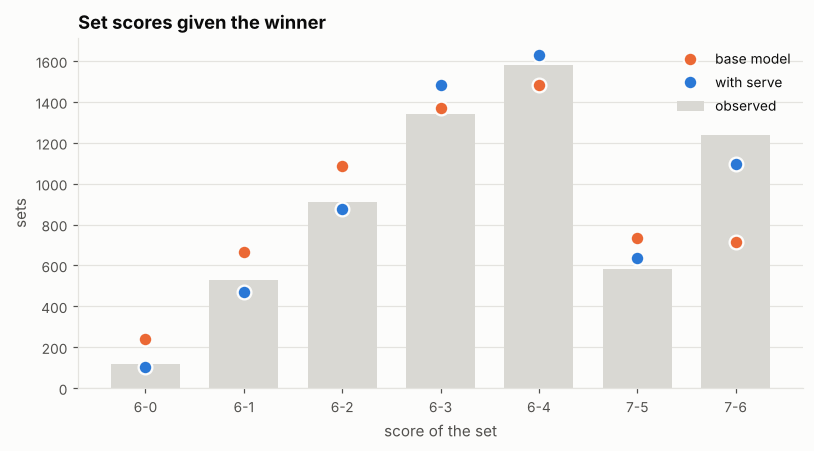

In [6]:
labels = ["%d-%d" % sc for sc in ex.SCORES]
idx = np.argwhere(N.sum(-1) > 0)
expected = {}
for name, mle in (("base", base), ("with serve", serve)):
    P = mle.predict()
    exp = np.zeros(len(labels))
    for i, j in idx:
        exp += N[i, j].sum() * P[i, j] / P[i, j].sum()
    expected[name] = exp
observed = N.sum((0, 1))

fig, ax = plt.subplots()
xx = np.arange(len(labels))
ax.bar(xx, observed, 0.7, color="#d9d8d3", label="observed")
ax.plot(xx, expected["base"], "o", color=ORANGE, markersize=9,
        markeredgecolor="#fcfcfb", markeredgewidth=1.5, label="base model")
ax.plot(xx, expected["with serve"], "o", color=BLUE, markersize=9,
        markeredgecolor="#fcfcfb", markeredgewidth=1.5, label="with serve")
ax.set_xticks(xx); ax.set_xticklabels(labels)
ax.grid(axis="x", visible=False)
ps.finish(ax, "Set scores given the winner", "score of the set", "sets", legend=True)
pd.DataFrame({"observed": observed, **{k: v.round(0) for k, v in expected.items()}},
             index=labels).T

The serve model fixes most of the misfit: about 1,100 tie-breaks expected
against about 1,240 observed (700 before), and 6-0 sets go from twice the
observed count to about it. Every score is now within about 12% of the data.
The remaining gaps (still some tie-breaks short; a few too many 6-3, 6-4 and
7-5 sets, too few 6-1) point to what a single global $\delta$ leaves out: big
servers, whose sets go to tie-breaks more often than average. A per-player
serve term would address them, at the cost of many weakly identified
parameters.

## 5. Strengths

Top 15 players with the serve model, with 95% intervals, against their
strengths in the base model. The scales differ (with the serve the point
probabilities move further from one half), so the comparison is about order.

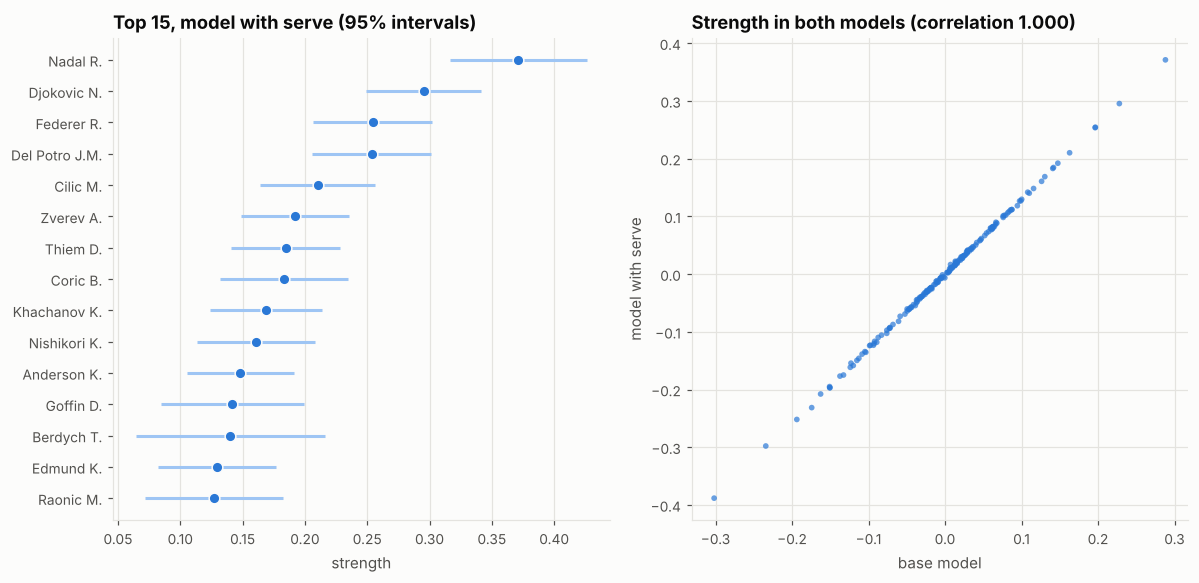

In [7]:
sb = base.summary().loc["strength"]
ss = serve.summary().loc["strength"].sort_values("estimate", ascending=False)
top = ss.head(15).iloc[::-1]

fig, axes = plt.subplots(1, 2, figsize=(11, 5.4))
ax = axes[0]
yy = np.arange(len(top))
ax.errorbar(top["estimate"], yy, xerr=1.96 * top["std_error"], fmt="o", color=BLUE,
            ecolor="#9ec5f4", elinewidth=2, markersize=7, markeredgecolor="#fcfcfb")
ax.set_yticks(yy); ax.set_yticklabels(top.index)
ax.grid(axis="y", visible=False)
ax.set_title("Top 15, model with serve (95% intervals)")
ax.set_xlabel("strength")
ax = axes[1]
ax.scatter(sb["estimate"], ss.loc[sb.index, "estimate"], s=14, color=BLUE, alpha=.7,
           edgecolor="none")
r = np.corrcoef(sb["estimate"], ss.loc[sb.index, "estimate"])[0, 1]
ax.set_title("Strength in both models (correlation %.3f)" % r)
ax.set_xlabel("base model"); ax.set_ylabel("model with serve")
plt.tight_layout()

## 6. Predictions and calibration

**Head-to-head** of the two strongest players: probability of winning a set
and the distribution of the set scores, in both models.

base       P(Nadal R. wins a set against Djokovic N.) = 0.606 +/- 0.053


with serve P(Nadal R. wins a set against Djokovic N.) = 0.620 +/- 0.054


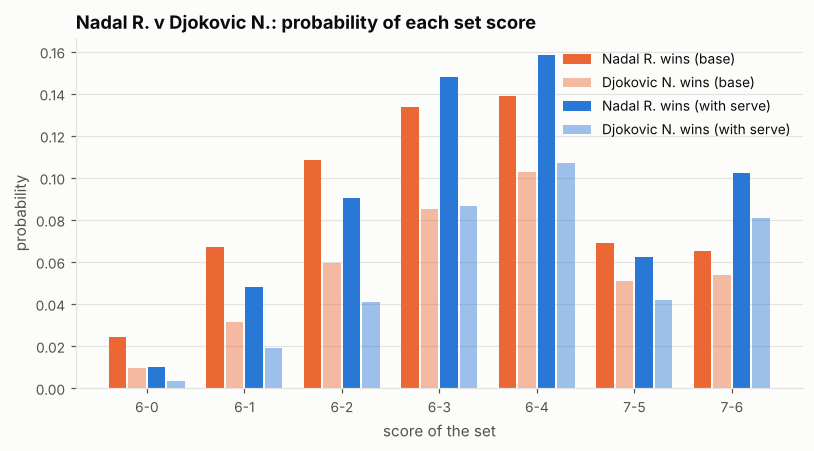

In [8]:
a, b = ss.index[0], ss.index[1]
i, j = players.index(a), players.index(b)
p_set = {}
for name, mle, model in (("base", base, ex.model()), ("with serve", serve, ex.serve_model())):
    value, se = mle.predict(Collapse(model, False, True), se=True)
    p_set[name] = value
    print("%-10s P(%s wins a set against %s) = %.3f +/- %.3f" % (name, a, b, value[i, j], se[i, j]))

fig, ax = plt.subplots()
w = 0.2
for k, (name, mle, color) in enumerate((("base", base, ORANGE), ("with serve", serve, BLUE))):
    P = mle.predict()
    ax.bar(xx + (k - 0.5) * 2 * w - w / 2, P[i, j], w - 0.02, color=color,
           label="%s wins (%s)" % (a, name))
    ax.bar(xx + (k - 0.5) * 2 * w + w / 2, P[j, i], w - 0.02, color=color, alpha=.45,
           label="%s wins (%s)" % (b, name))
ax.set_xticks(xx); ax.set_xticklabels(labels)
ax.grid(axis="x", visible=False)
ps.finish(ax, "%s v %s: probability of each set score" % (a, b), "score of the set",
          "probability", legend=True)

With the serve the probability moves from one-sided scores (6-0 to 6-2)
to close ones (6-3, 6-4 and above all 7-6), while the overall probability of
winning the set hardly changes.

**Calibration** of the set-win probabilities. The data list the winner first,
so the order of the two players is drawn at random (fixed seed).

base       log score of the winner -0.6288
with serve log score of the winner -0.6273


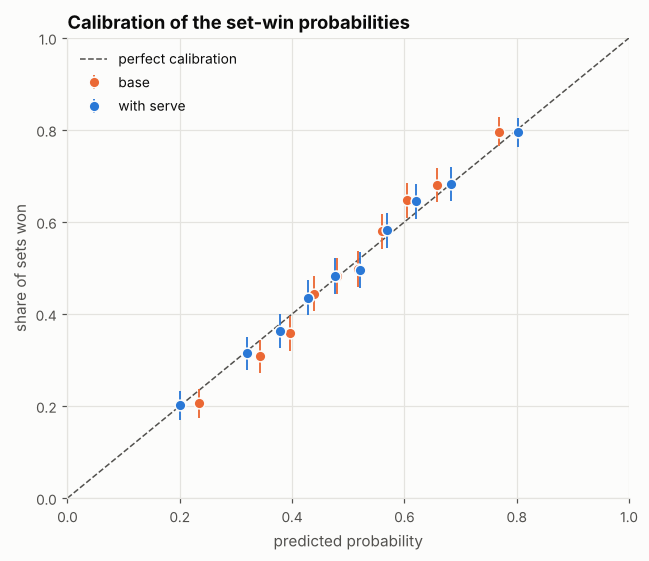

In [9]:
code = {name: k for k, name in enumerate(players)}
w_ = np.where(sets["score1"] > sets["score2"], sets["player1"], sets["player2"])
l_ = np.where(sets["score1"] > sets["score2"], sets["player2"], sets["player1"])
winner, loser = pd.Series(w_).map(code).values, pd.Series(l_).map(code).values
flip = np.random.default_rng(0).random(len(sets)) < 0.5
i1, i2 = np.where(flip, loser, winner), np.where(flip, winner, loser)
won = (~flip).astype(float)

fig, ax = plt.subplots(figsize=(6, 5.2))
ax.plot([0, 1], [0, 1], color=TEXT_2, lw=1, ls="--", label="perfect calibration")
for name, color in (("base", ORANGE), ("with serve", BLUE)):
    pred = p_set[name][i1, i2]
    bins = pd.qcut(pred, 10, duplicates="drop")
    g = pd.DataFrame({"p": pred, "won": won}).groupby(bins, observed=True)
    mp, mw, n = g["p"].mean(), g["won"].mean(), g["won"].count()
    ax.errorbar(mp, mw, yerr=1.96 * np.sqrt(mw * (1 - mw) / n), fmt="o", color=color,
                markersize=7, elinewidth=1.2, markeredgecolor="#fcfcfb", label=name)
    print("%-10s log score of the winner %.4f" % (name, np.mean(np.log(np.where(won == 1, pred, 1 - pred)))))
ax.set_xlim(0, 1); ax.set_ylim(0, 1)
ps.finish(ax, "Calibration of the set-win probabilities", "predicted probability",
          "share of sets won", legend=True)

## 7. Conclusions

- One global serve parameter changes the fit a lot: equal players win about
  61% of their service points and hold about 77% of their service games. The
  likelihood ratio is about 470 for one extra parameter.
- The shape of the sets is much closer to the data, every score within about
  12%. The tie-breaks go from about 700 expected to about 1,100, against
  1,240 observed.
- Who wins a set is predicted about as well as before: the serve changes how
  sets are won, much less by whom.
- Next refinements: a per-player serve term (big servers), regularised; and
  the order of serve across the sets of a match, which the set-level data
  ignore.